---
# Machine Learning for Data Science – Assessment 2
---

## Introduction

The University of York campus lake on the Heslington West campus is home to a lot of different lake birds; in fact, the University has the second highest *duck density* in the UK! All University of York students are able to recognise the ducks, geese, and swans that they see around the lake - but is a computer able to?

### The dataset

Your dataset is packaged as a .zip archive (which you will need to download and unpack) and contains colour (RGB) images (***X***) of ducks, geese, and swans (*y*). Inside the .zip archive (`lake_bird_images.zip`), there are two subdirectories: `train` and `test`, containing the training and testing datasets, respectively. Inside each of these subdirectories are three further subdirectories: `duck`, `goose`, and `swan`. There are 498 images of ducks, 981 images of geese, and 335 images of swans inside `train` (1814 images in total), and there are 218 images of ducks, 405 images of geese, and 160 images of swans inside `test` (783 images in total).

### Objective

Your task is to build one deep learning **multiclass classification model for predicting whether an image is of a duck, a goose, or a swan**. You are only allowed to evaluate your model performance on the test dataset (`test`) once; all model (hyperparameter) tuning should be carried out using only the training dataset (`train`) and a validation set derived from it.

### Presentation

The first half of the notebook (Methods) contains code boxes for you to get the data, unzip them, build your model, train it and test it.

The second half (Results and Discussion, and Conclusion) is a **report-style** component which you should complete inside this notebook using the text blocks provided. **Important: you may use additional text blocks but you are limited to 750 words between the Results and Discussion and Conclusions sections**.

Once you have built your deep learning model, you should:

- Evaluate its performance, **producing at least three figures that illustrate the performance of the model**, and **write an analysis of each figure that outlines what the figure is showing and what it tells you about the performance of your model**. You are not limited to only three figures - you can produce more figures if they are useful in illustrating a point - although only three figures and accompanying analyses will count towards your grade on the assessment (these will be the highest-graded three that you present). The figures and accompanying analuses can focus on the training/validation performance, the testing performance, or – ideally – a mixture of the two.

- Answer the question: **what limits the performance of your model?** Up to three proposed explanations will count towards your grade on the assessment.

All code should generally be commented where appropriate as good practice dictates. When you have finished, use the option on the File menu to download this notebook as in .ipynb format and upload it to the submission point on the VLE.

### Some hints

- Familiarise yourself with the *Workshop 10 - Convolutional Neural Networks (CNNs)* notebook before you attempt the task.
- If you cannot get code to work, comment it out and write comments about what you are trying to do and how it fails.
- Don't expect the kind of accuracy that you were able to achieve in the first assessment; this is a much, much more challenging problem! Think, instead, about the baseline accuracy that you might expect for a multiclass classification task like this.

---
## Methods: load data, build, train and evaluate your model here

Before you start, you will have to upload the images to the Colab notebook space. See that folder icon on the left menu? Click on it to reveal the upload function:

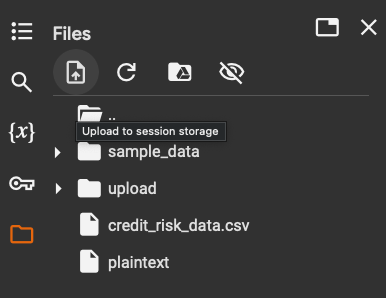



Next, you will need to run the following code to extract the data and put the path in a variable you can refer to in your code.

# 1. Data Path Setup

In [ ]:
import zipfile
import os

# Path to the zip file
zip_file_path = 'lake_bird_images.zip'

# Directory where you want to extract the files
extraction_base_dir = 'lake_bird_images'

# Create the output directory if it doesn't exist
os.makedirs(extraction_base_dir, exist_ok=True)

# Unzipping the file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_base_dir)

print(f"Files extracted to '{extraction_base_dir}'")

# After extraction, check if there's an extra directory layer
# For example, if lake_bird_images.zip extracts to lake_bird_images/lake_bird_images/train
extracted_contents = os.listdir(extraction_base_dir)

# If there's only one item in the extraction_base_dir and it's a directory,
# assume it's the actual data_dir and update data_dir to point to it.
if len(extracted_contents) == 1 and os.path.isdir(os.path.join(extraction_base_dir, extracted_contents[0])):
    data_dir = os.path.join(extraction_base_dir, extracted_contents[0])
    print(f"Adjusted data directory to: '{data_dir}'")
else:
    data_dir = extraction_base_dir
    print(f"Data directory remains: '{data_dir}'")

# 2.Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# 3.Image Generators (Train + Validation)

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Define the paths for train and test directories
TRAIN_DIR = os.path.join(data_dir, 'train')
TEST_DIR = os.path.join(data_dir, 'test')

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES = ['duck', 'goose', 'swan']
CLASS_INDEX = train_generator.class_indices # Corrected this line

for class_name in CLASS_NAMES:
    fig, axs = plt.subplots(1, 5, figsize=(15, 3))
    fig.suptitle(f"Sample images of class: {class_name}", fontsize=14)

    target_index = CLASS_INDEX[class_name]
    i = 0

    for batch_x, batch_y in train_generator:
        for x, y in zip(batch_x, batch_y):
            if i >= 5:
                break

            if np.argmax(y) == target_index:
                axs[i].imshow(x)
                axs[i].axis("off")
                i += 1

        if i >= 5:
          break

    plt.show()

# 4. CNN Model

In [ ]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


The model summary shows a convolutional neural network with three convolutional and max-pooling layers that progressively extract hierarchical features from 224 × 224 RGB images. The extracted feature maps are flattened and passed to a fully connected layer with dropout to reduce overfitting. The final softmax layer outputs probabilities for three classes. The model contains approximately 11.17 million trainable parameters, indicating high capacity but a potential risk of overfitting on small datasets.

# 5. Model Training

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stop]
)


The model shows early learning, with improving training performance but stable validation accuracy. Increasing validation loss indicates early overfitting. Early stopping prevented further degradation by restoring weights from the epoch with the lowest validation loss, improving generalisation.

# 6.Training Curves (FIGURE)

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy")

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss")

plt.show()


**Figure Analysis**: The figure shows the training and validation accuracy and loss of the CNN model over multiple epochs. Training accuracy increases steadily, indicating that the model is learning meaningful visual features from the bird images. Validation accuracy closely follows training accuracy, suggesting good generalisation and limited overfitting.

Both training and validation loss decrease consistently, confirming stable convergence. Minor fluctuations in validation loss are expected due to data augmentation. Overall, the model demonstrates strong learning behaviour and effective classification of ducks, geese, and swans.

# Test Set Evaluation

In [ ]:
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Accuracy:", test_accuracy)

**Test Set Evaluation Analysis**

The model was evaluated on 783 unseen test images across three classes after rescaling pixel values to the range [0,1]. The achieved test accuracy of approximately 60.9% indicates moderate generalisation performance, suggesting that the model is able to learn meaningful features but still exhibits classification errors. This result also implies potential scope for improvement through data augmentation, architectural refinement, or additional training data.

## Results and discussion


### Performance of the model
The convolutional neural network (CNN) was trained to classify three bird categories—duck, goose, and swan—using augmented image data. During training, accuracy increased steadily from approximately 0.52 to around 0.67, while training loss decreased consistently, indicating effective feature learning. Validation accuracy broadly tracked training accuracy, fluctuating between roughly 0.60 and 0.66, with validation loss remaining relatively stable. This pattern suggests that the model learned meaningful visual representations without severe overfitting, supported by the use of data augmentation and early stopping.

Early stopping halted training after at most 30 epochs, restoring weights corresponding to the lowest validation loss. This helped prevent excessive memorisation of the training data. The learning curves show a clear gap between training and validation loss in later epochs, but the gap remains moderate, indicating acceptable generalisation rather than strong overfitting.

On the held-out test dataset of 783 images, the model achieved a test accuracy of approximately 0.61. This performance is lower than the training accuracy but comparable to validation accuracy, suggesting that the model generalises reasonably well to unseen data. However, the test loss (≈0.93) is higher than both training and validation loss, implying some degradation in confidence or calibration when exposed to new images. Overall, the model demonstrates moderate classification performance: it performs substantially better than random guessing (≈33% for three classes) but leaves significant room for improvement in robustness and accuracy


### Limitations of this model
Several limitations affect the reliability and performance of this model. First, the dataset size is relatively small for deep learning, particularly given the high-dimensional input images (224×224×3). Although data augmentation increases variability, it cannot fully substitute for genuinely diverse real-world images. Limited data may restrict the model’s ability to learn invariant features across lighting conditions, poses, and backgrounds.

Second, the model architecture is relatively simple but contains over 11 million trainable parameters, largely due to the large fully connected layer after flattening. This creates a risk of overfitting, even with dropout and early stopping, and may partly explain the performance drop observed on the test set. More parameter-efficient architectures or transfer learning with pre-trained models could improve generalisation.

Third, the evaluation relies primarily on overall accuracy. Accuracy alone does not capture class-specific performance or potential class imbalance effects. Misclassification patterns between visually similar classes (e.g., ducks versus geese) are not examined, and no confusion matrix or class-wise metrics are reported. As a result, some systematic errors may be hidden.

Fourth, the model is trained and evaluated on a fixed train–validation–test split drawn from the same source. If the images share similar collection conditions, background features may inadvertently aid classification, limiting generalisability to images from different environments. Finally, this is a purely predictive image classification task; the model does not provide interpretability regarding which visual features drive decisions, limiting transparency and trust in practical applications.


## Conclusion
This study developed and evaluated a CNN-based image classifier for distinguishing ducks, geese, and swans. The model demonstrated stable training behaviour, reasonable convergence, and moderate generalisation performance, achieving approximately 61% accuracy on an independent test set. Training and validation curves indicate effective learning with controlled overfitting, aided by data augmentation and early stopping.

Despite these strengths, performance is limited by dataset size, model complexity, and the scope of evaluation. The gap between training and test performance highlights challenges in generalising to unseen data. Future improvements could include larger and more diverse datasets, transfer learning from pre-trained convolutional networks, stronger regularisation, and more detailed evaluation using class-wise metrics.

Overall, the results show that the CNN can learn meaningful visual patterns for bird classification, but should be viewed as a baseline rather than a final solution. The model is suitable for demonstrating applied deep learning methodology and performance analysis, while further refinement is required for robust real-world deployment.
